<a href="https://colab.research.google.com/github/shashigharti/DataTablesReload/blob/master/dinov3_upernet.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -U kaggle

### Kaggle Authentication and Dataset Setup

To download datasets from Kaggle, make sure you have your `kaggle.json` API token uploaded.
Alternatively, you can save your Kaggle credentials to your Colab Secrets (as `KAGGLE_USERNAME` and `KAGGLE_KEY`).

In [ ]:
import os
from google.colab import userdata

try:
    os.environ['KAGGLE_USERNAME'] = userdata.get('KAGGLE_USERNAME')
    os.environ['KAGGLE_KEY'] = userdata.get('KAGGLE_KEY')
    print("Kaggle API credentials set successfully from secrets!")
except Exception:
    print("Could not load Kaggle secrets automatically. Please ensure ~/.kaggle/kaggle.json is configured manually if download fails.")

Kaggle API credentials set successfully from secrets!


In [ ]:
import os

dataset_dir = "water_bodies_dataset/Water Bodies Dataset"

if not os.path.exists(dataset_dir):
    print("Dataset not found. Downloading and extracting...")
    !rm -rf water_bodies_dataset *.zip
    !kaggle datasets download -d franciscoescobar/satellite-images-of-water-bodies --force
    !mkdir -p water_bodies_dataset
    !unzip -qo satellite-images-of-water-bodies.zip -d water_bodies_dataset
    print("Download and extraction completed!")
else:
    print("Dataset already exists. Skipping download.")

!ls -la water_bodies_dataset

Dataset already exists. Skipping download.
total 12
drwxr-xr-x 3 root root 4096 Nov 26 04:05  .
drwxr-xr-x 1 root root 4096 Nov 26 04:11  ..
drwxr-xr-x 4 root root 4096 Nov 26 04:05 'Water Bodies Dataset'


In [ ]:
!find water_bodies_dataset -maxdepth 3 -type d

water_bodies_dataset
water_bodies_dataset/Water Bodies Dataset
water_bodies_dataset/Water Bodies Dataset/Masks
water_bodies_dataset/Water Bodies Dataset/Images


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from transformers import AutoModel, UperNetConfig
from transformers.models.upernet.modeling_upernet import UperNetHead


class DinoV3UperNet(nn.Module):
    """
    Frozen DINOv3 ViT-S/16 backbone -> fixed neck -> UPerNet head.
    Input:  (B, 3, 256, 256) RGB image
    Output: (B, 2, 256, 256) logits for background / water
    """

    def __init__(self,
                 model_name="facebook/dinov3-vits16-pretrain-lvd1689m",
                 num_labels=2):
        super().__init__()

        # Backbone (DinoV3 ViT/S2)
        self.backbone = AutoModel.from_pretrained(model_name)
        for param in self.backbone.parameters():
            param.requires_grad = False

        cfg = self.backbone.config
        self.hidden_size = getattr(cfg, "hidden_size", 384)              # 384 for ViT-S
        self.patch_size = getattr(cfg, "patch_size", 16)                 # 16
        self.num_extra_tokens = 1 + getattr(cfg, "num_register_tokens", 4)

        # No learning happens here
        self.scales = [4.0, 2.0, 1.0, 0.5]   # 16x16 grid -> 64, 32, 16, 8

        head_config = UperNetConfig(
            num_labels=num_labels,
            hidden_size=512,
            use_auxiliary_head=False,
        )
        self.head = UperNetHead(head_config, in_channels=[self.hidden_size] * 4)

    def train(self, mode=True):
        super().train(mode)
        self.backbone.eval()
        return self

    def neck(self, tokens, grid_h, grid_w):
        # tokens: (B, 261, 384)
        patches = tokens[:, self.num_extra_tokens:, :]          # (B, 256, 384)  drop CLS + registers
        B = patches.shape[0]
        fmap = patches.transpose(1, 2).reshape(B, self.hidden_size, grid_h, grid_w)  # (B, 384, 16, 16)

        features = []
        for s in self.scales:
            if s > 1:
                features.append(F.interpolate(fmap, scale_factor=s, mode="bilinear", align_corners=False))
            elif s == 1:
                features.append(fmap)
            else:
                features.append(F.max_pool2d(fmap, kernel_size=int(1 / s)))
        return features                                          # [64x64, 32x32, 16x16, 8x8], each 384 channels

    def forward(self, pixel_values):
        B, _, H, W = pixel_values.shape
        grid_h, grid_w = H // self.patch_size, W // self.patch_size   # 16, 16

        with torch.no_grad():
            outputs = self.backbone(pixel_values=pixel_values)
            tokens = outputs.last_hidden_state                   # (B, 261, 384)

        features = self.neck(tokens, grid_h, grid_w)

        logits = self.head(features)                             # (B, 2, 64, 64)

        logits = F.interpolate(logits, size=(H, W), mode="bilinear", align_corners=False)
        return logits                                            # (B, 2, 256, 256)

In [ ]:
CONFIG = {
    "data_source": "kaggle",      # "kaggle" for testing, "geotiff" for the real <1 m data
    "data_dir":    dataset_dir,
    "img_size":    256,           # must be a multiple of 16
    "max_gsd":     1.0,           # metres per pixel; GeoTIFF chips coarser than this are rejected
    "batch_size":  8,
    "epochs":      10,
    "lr":          1e-4,
    "val_split":   0.15,     # 15% validation
    "test_split":  0.15,     # 15% test (the remaining 70% is training)
    "seed":        42,
}

In [ ]:
import os, glob, random
import numpy as np
import torch
from PIL import Image
from torch.utils.data import Dataset

MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
STD  = np.array([0.229, 0.224, 0.225], dtype=np.float32)

DEVICE      = "cuda" if torch.cuda.is_available() else "cpu"

class BaseWaterDataset(Dataset):
    """Shared logic. Subclasses only define how to read an image and a mask."""

    def __init__(self, samples, img_size=256, augment=False):
        self.samples = samples
        self.img_size = img_size
        self.augment = augment

    def load_image(self, path):         # must return float32 array (H, W, 3), values 0-1
        raise NotImplementedError

    def load_mask(self, path):          # must return int64 array (H, W), 0 = background, 1 = water
        raise NotImplementedError

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        img_path, mask_path = self.samples[idx]
        image = self.load_image(img_path)
        mask  = self.load_mask(mask_path)

        if self.augment:
            if random.random() < 0.5:
                image, mask = image[:, ::-1], mask[:, ::-1]
            if random.random() < 0.5:
                image, mask = image[::-1, :], mask[::-1, :]

        image = (image - MEAN) / STD
        image = torch.from_numpy(image.copy()).permute(2, 0, 1).float()   # (3, H, W)
        mask  = torch.from_numpy(mask.copy()).long()                      # (H, W)
        return image, mask


class KaggleWaterDataset(BaseWaterDataset):
    """Sentinel-2 JPGs (~10 m). For pipeline testing only."""

    def load_image(self, path):
        img = Image.open(path).convert("RGB").resize((self.img_size,) * 2, Image.BILINEAR)
        return np.asarray(img, dtype=np.float32) / 255.0

    def load_mask(self, path):
        m = Image.open(path).convert("L").resize((self.img_size,) * 2, Image.NEAREST)
        return (np.asarray(m) > 127).astype(np.int64)


class GeoTiffWaterDataset(BaseWaterDataset):
    """Real data: 3-band RGB GeoTIFF chips (<1 m GSD) with matching mask GeoTIFFs."""

    def __init__(self, samples, img_size=256, augment=False, max_gsd=1.0):
        super().__init__(samples, img_size, augment)
        self.max_gsd = max_gsd

    def load_image(self, path):
        import rasterio
        with rasterio.open(path) as src:
            gsd = abs(src.res[0])
            # Only checks chips in metre-based projections (e.g. UTM, Web Mercator)
            if src.crs and src.crs.is_projected and gsd >= self.max_gsd:
                raise ValueError(f"{path}: GSD {gsd:.2f} m is not below {self.max_gsd} m")
            img = src.read([1, 2, 3]).transpose(1, 2, 0).astype(np.float32)   # (H, W, 3)
        if img.shape[:2] != (self.img_size, self.img_size):
            raise ValueError(f"{path}: expected {self.img_size}x{self.img_size}, got {img.shape[:2]}")
        return img / 255.0 if img.max() > 1 else img

    def load_mask(self, path):
        import rasterio
        with rasterio.open(path) as src:
            m = src.read(1)
        return (m > 0).astype(np.int64)

In [ ]:
DATASET_CLASSES = {
    "kaggle":  KaggleWaterDataset,
    "geotiff": GeoTiffWaterDataset,
}

def find_samples(cfg):
    """Pairs each image with its mask. Adjust folder names here if they differ."""
    if cfg["data_source"] == "kaggle":
        imgs = sorted(glob.glob(os.path.join(cfg["data_dir"], "Images", "*.jpg")))
        mask_dir = os.path.join(cfg["data_dir"], "Masks")
    elif cfg["data_source"] == "geotiff":
        imgs = sorted(glob.glob(os.path.join(cfg["data_dir"], "images", "*.tif")))
        mask_dir = os.path.join(cfg["data_dir"], "masks")
    else:
        raise ValueError(f"Unknown data_source: {cfg['data_source']}")
    return [(p, os.path.join(mask_dir, os.path.basename(p))) for p in imgs]


def split_samples(samples, val_split, test_split, seed):
    """Shuffle once, then cut into train / val / test. No overlap between sets."""
    if val_split + test_split >= 1:
        raise ValueError("val_split + test_split must be less than 1")

    samples = samples.copy()
    random.Random(seed).shuffle(samples)

    n_total = len(samples)
    n_test  = int(n_total * test_split)
    n_val   = int(n_total * val_split)

    test  = samples[:n_test]
    val   = samples[n_test:n_test + n_val]
    train = samples[n_test + n_val:]
    return train, val, test


def build_datasets(cfg):
    samples = find_samples(cfg)
    if not samples:
        raise FileNotFoundError(f"No images found in {cfg['data_dir']}")

    train_s, val_s, test_s = split_samples(
        samples, cfg["val_split"], cfg["test_split"], cfg["seed"]
    )

    cls = DATASET_CLASSES[cfg["data_source"]]
    extra = {"max_gsd": cfg["max_gsd"]} if cfg["data_source"] == "geotiff" else {}

    train_ds = cls(train_s, cfg["img_size"], augment=True,  **extra)   # only train is augmented
    val_ds   = cls(val_s,   cfg["img_size"], augment=False, **extra)
    test_ds  = cls(test_s,  cfg["img_size"], augment=False, **extra)

    print(f"Train: {len(train_ds)} | Val: {len(val_ds)} | Test: {len(test_ds)}")
    return train_ds, val_ds, test_ds

In [ ]:
import os, glob, random
import numpy as np
import torch
from PIL import Image
from torch.utils.data import Dataset

MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
STD  = np.array([0.229, 0.224, 0.225], dtype=np.float32)

DEVICE      = "cuda" if torch.cuda.is_available() else "cpu"

class BaseWaterDataset(Dataset):
    """Shared logic. Subclasses only define how to read an image and a mask."""

    def __init__(self, samples, img_size=256, augment=False):
        self.samples = samples
        self.img_size = img_size
        self.augment = augment

    def load_image(self, path):         # must return float32 array (H, W, 3), values 0-1
        raise NotImplementedError

    def load_mask(self, path):          # must return int64 array (H, W), 0 = background, 1 = water
        raise NotImplementedError

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        img_path, mask_path = self.samples[idx]
        image = self.load_image(img_path)
        mask  = self.load_mask(mask_path)

        if self.augment:
            if random.random() < 0.5:
                image, mask = image[:, ::-1], mask[:, ::-1]
            if random.random() < 0.5:
                image, mask = image[::-1, :], mask[::-1, :]

        image = (image - MEAN) / STD
        image = torch.from_numpy(image.copy()).permute(2, 0, 1).float()   # (3, H, W)
        mask  = torch.from_numpy(mask.copy()).long()                      # (H, W)
        return image, mask


class KaggleWaterDataset(BaseWaterDataset):
    """Sentinel-2 JPGs (~10 m). For pipeline testing only."""

    def load_image(self, path):
        img = Image.open(path).convert("RGB").resize((self.img_size,) * 2, Image.BILINEAR)
        return np.asarray(img, dtype=np.float32) / 255.0

    def load_mask(self, path):
        m = Image.open(path).convert("L").resize((self.img_size,) * 2, Image.NEAREST)
        return (np.asarray(m) > 127).astype(np.int64)


class GeoTiffWaterDataset(BaseWaterDataset):
    """Real data: 3-band RGB GeoTIFF chips (<1 m GSD) with matching mask GeoTIFFs."""

    def __init__(self, samples, img_size=256, augment=False, max_gsd=1.0):
        super().__init__(samples, img_size, augment)
        self.max_gsd = max_gsd

    def load_image(self, path):
        import rasterio
        with rasterio.open(path) as src:
            gsd = abs(src.res[0])
            # Only checks chips in metre-based projections (e.g. UTM, Web Mercator)
            if src.crs and src.crs.is_projected and gsd >= self.max_gsd:
                raise ValueError(f"{path}: GSD {gsd:.2f} m is not below {self.max_gsd} m")
            img = src.read([1, 2, 3]).transpose(1, 2, 0).astype(np.float32)   # (H, W, 3)
        if img.shape[:2] != (self.img_size, self.img_size):
            raise ValueError(f"{path}: expected {self.img_size}x{self.img_size}, got {img.shape[:2]}")
        return img / 255.0 if img.max() > 1 else img

    def load_mask(self, path):
        import rasterio
        with rasterio.open(path) as src:
            m = src.read(1)
        return (m > 0).astype(np.int64)

In [ ]:
import time
from datetime import datetime, timedelta

def now_str():
    return datetime.now().strftime("%Y-%m-%d %H:%M:%S")

def fmt_duration(seconds):
    return str(timedelta(seconds=int(seconds)))     # e.g. 0:03:27

In [ ]:
def dice_loss(logits, target, eps=1e-6):
    probs = F.softmax(logits, dim=1)[:, 1]
    target = target.float()
    inter = (probs * target).sum(dim=(1, 2))
    union = probs.sum(dim=(1, 2)) + target.sum(dim=(1, 2))
    return 1 - ((2 * inter + eps) / (union + eps)).mean()

ce = nn.CrossEntropyLoss()

def loss_fn(logits, target):
    return ce(logits, target) + dice_loss(logits, target)


def update_iou(logits, target, stats):
    pred = logits.argmax(dim=1)
    stats["inter"] += ((pred == 1) & (target == 1)).sum().item()
    stats["union"] += ((pred == 1) | (target == 1)).sum().item()

In [ ]:
from torch.utils.data import DataLoader

train_ds, val_ds, test_ds = build_datasets(CONFIG)
train_loader = DataLoader(train_ds, batch_size=CONFIG["batch_size"], shuffle=True,  num_workers=2, drop_last=True)
val_loader   = DataLoader(val_ds,   batch_size=CONFIG["batch_size"], shuffle=False, num_workers=2, drop_last=True)
test_loader  = DataLoader(test_ds,  batch_size=CONFIG["batch_size"], shuffle=False, num_workers=2, drop_last=True)
print(f"Train: {len(train_ds)}  |  Val: {len(val_ds)}")

model = DinoV3UperNet(num_labels=2).to(DEVICE)
optimizer = torch.optim.AdamW(model.head.parameters(), lr=CONFIG["lr"], weight_decay=1e-4)   # head only
scaler = torch.amp.GradScaler("cuda", enabled=(DEVICE == "cuda"))

train_start_time = now_str()
start = time.time()
print(f"[{train_start_time}] Training started: {CONFIG['epochs']} epochs on {DEVICE}")


best_iou = 0.0
history = {"train_loss": [], "val_loss": [], "val_iou": []}
for epoch in range(1, CONFIG["epochs"] + 1):

    model.train()
    train_loss = 0.0
    for images, masks in train_loader:
        images, masks = images.to(DEVICE), masks.to(DEVICE)

        optimizer.zero_grad()
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(DEVICE == "cuda")):
            logits = model(images)                    # forward pass
            loss = loss_fn(logits, masks)             # loss

        scaler.scale(loss).backward()                 # backward pass
        scaler.step(optimizer)                        # update weights
        scaler.update()
        train_loss += loss.item()

    model.eval()
    val_loss, stats = 0.0, {"inter": 0, "union": 0}
    with torch.no_grad():
        for images, masks in val_loader:
            images, masks = images.to(DEVICE), masks.to(DEVICE)
            logits = model(images)
            val_loss += loss_fn(logits, masks).item()
            update_iou(logits, masks, stats)


    val_iou = stats["inter"] / max(stats["union"], 1)
    print(f"Epoch {epoch:02d} | train loss {train_loss/len(train_loader):.4f} "
          f"| val loss {val_loss/len(val_loader):.4f} | val IoU {val_iou:.4f}")
    history["train_loss"].append(train_loss / len(train_loader))
    history["val_loss"].append(val_loss / len(val_loader))
    history["val_iou"].append(val_iou)

    if val_iou > best_iou:
        best_iou = val_iou
        torch.save(model.head.state_dict(), "best_head.pt")
        print(f"  -> saved new best (IoU {best_iou:.4f})")

print(f"Done. Best val IoU: {best_iou:.4f}")
train_end_time = now_str()
train_time = time.time() - start
print(f"[{train_end_time}] Training finished in {fmt_duration(train_time)} "
      f"| best val IoU {best_iou:.4f} at epoch {best_epoch}")

Train: 1989 | Val: 426 | Test: 426
Train: 1989  |  Val: 426


Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

Epoch 01 | train loss 0.7322 | val loss 0.6425 | val IoU 0.6715
  -> saved new best (IoU 0.6715)
Epoch 02 | train loss 0.6163 | val loss 0.5845 | val IoU 0.6918
  -> saved new best (IoU 0.6918)
Epoch 03 | train loss 0.5799 | val loss 0.5626 | val IoU 0.7006
  -> saved new best (IoU 0.7006)
Epoch 04 | train loss 0.5432 | val loss 0.5619 | val IoU 0.6975
Epoch 05 | train loss 0.5305 | val loss 0.5577 | val IoU 0.7076
  -> saved new best (IoU 0.7076)
Epoch 06 | train loss 0.5004 | val loss 0.5505 | val IoU 0.7104
  -> saved new best (IoU 0.7104)
Epoch 07 | train loss 0.4948 | val loss 0.5567 | val IoU 0.7116
  -> saved new best (IoU 0.7116)
Epoch 08 | train loss 0.4728 | val loss 0.5335 | val IoU 0.7196
  -> saved new best (IoU 0.7196)
Epoch 09 | train loss 0.4562 | val loss 0.5041 | val IoU 0.7320
  -> saved new best (IoU 0.7320)
Epoch 10 | train loss 0.4516 | val loss 0.5690 | val IoU 0.7088
Done. Best val IoU: 0.7320


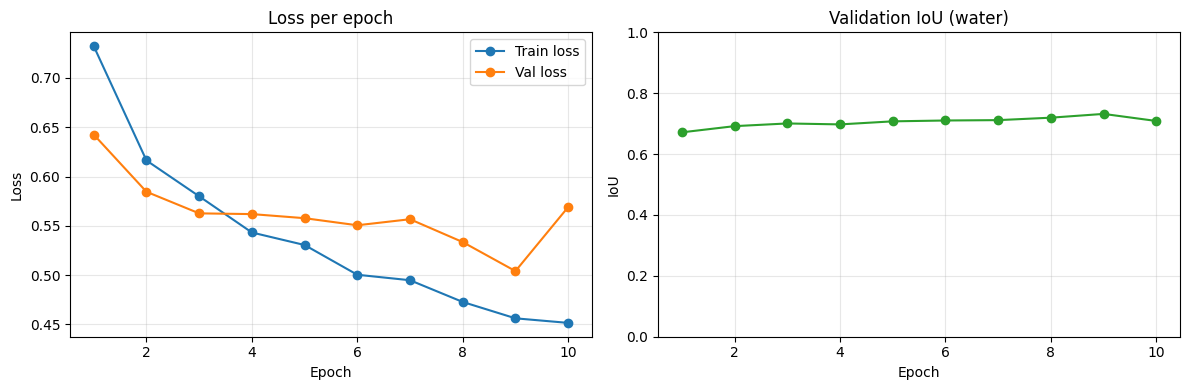

In [ ]:
import matplotlib.pyplot as plt
SAVE_DIR = "."

def plot_history(history, save_path=None):
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

    ax1.plot(epochs, history["train_loss"], marker="o", label="Train loss")
    ax1.plot(epochs, history["val_loss"],   marker="o", label="Val loss")
    ax1.set_title("Loss per epoch")
    ax1.set_xlabel("Epoch"); ax1.set_ylabel("Loss")
    ax1.legend(); ax1.grid(alpha=0.3)

    ax2.plot(epochs, history["val_iou"], marker="o", color="tab:green")
    ax2.set_title("Validation IoU (water)")
    ax2.set_xlabel("Epoch"); ax2.set_ylabel("IoU")
    ax2.set_ylim(0, 1); ax2.grid(alpha=0.3)

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150)
    plt.show()

plot_history(history, save_path=os.path.join(SAVE_DIR, "training_curves.png"))

Test results
  loss       0.5484
  iou        0.7252
  precision  0.8448
  recall     0.8367
  f1         0.8407


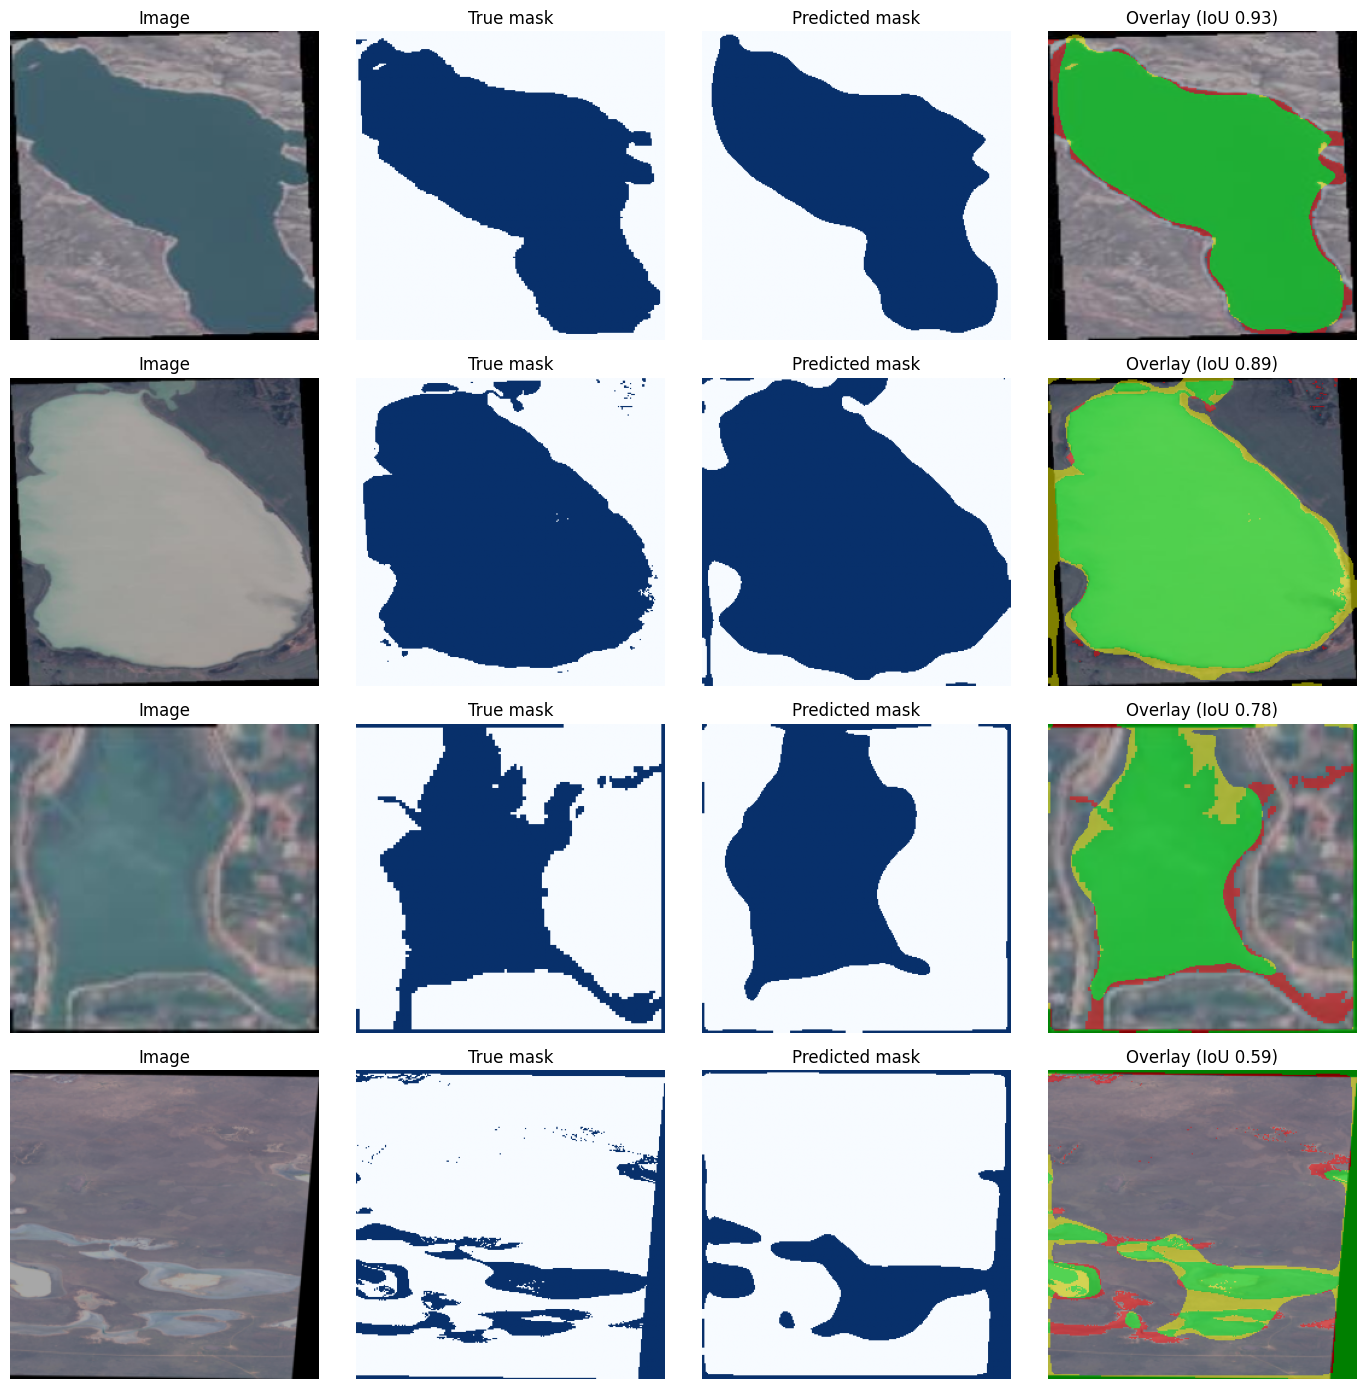

In [ ]:
import numpy as np
import torch
import matplotlib.pyplot as plt

def denormalize(image_tensor):
    """Undo the ImageNet normalisation so the image displays correctly."""
    img = image_tensor.cpu().permute(1, 2, 0).numpy()
    img = img * STD + MEAN
    return np.clip(img, 0, 1)

@torch.no_grad()
def show_predictions(model, dataset, n=4, save_path=None):
    model.eval()
    indices = np.random.choice(len(dataset), size=min(n, len(dataset)), replace=False)
    fig, axes = plt.subplots(len(indices), 4, figsize=(14, 3.5 * len(indices)))
    axes = np.atleast_2d(axes)

    for row, idx in enumerate(indices):
        image, mask = dataset[idx]
        logits = model(image.unsqueeze(0).to(DEVICE))
        pred = logits.argmax(dim=1)[0].cpu().numpy()
        mask = mask.numpy()

        # IoU for this single image
        inter = ((pred == 1) & (mask == 1)).sum()
        union = ((pred == 1) | (mask == 1)).sum()
        iou = inter / union if union > 0 else 1.0

        rgb = denormalize(image)

        # Overlay: green = correct water, red = missed water, yellow = false water
        overlay = rgb.copy()
        overlay[(pred == 1) & (mask == 1)] = [0, 1, 0]
        overlay[(pred == 0) & (mask == 1)] = [1, 0, 0]
        overlay[(pred == 1) & (mask == 0)] = [1, 1, 0]
        blended = 0.5 * rgb + 0.5 * overlay

        panels = [
            (rgb,     "Image"),
            (mask,    "True mask"),
            (pred,    "Predicted mask"),
            (blended, f"Overlay (IoU {iou:.2f})"),
        ]
        for col, (data, title) in enumerate(panels):
            ax = axes[row, col]
            ax.imshow(data, cmap="Blues" if data.ndim == 2 else None, vmin=0, vmax=1)
            ax.set_title(title); ax.axis("off")

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150)
    plt.show()

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    tp = fp = fn = 0
    total_loss = 0.0
    for images, masks in loader:
        images, masks = images.to(DEVICE), masks.to(DEVICE)
        logits = model(images)
        total_loss += loss_fn(logits, masks).item()
        pred = logits.argmax(dim=1)
        tp += ((pred == 1) & (masks == 1)).sum().item()
        fp += ((pred == 1) & (masks == 0)).sum().item()
        fn += ((pred == 0) & (masks == 1)).sum().item()

    iou       = tp / max(tp + fp + fn, 1)
    precision = tp / max(tp + fp, 1)
    recall    = tp / max(tp + fn, 1)
    f1        = 2 * precision * recall / max(precision + recall, 1e-8)
    return {"loss": total_loss / len(loader), "iou": iou,
            "precision": precision, "recall": recall, "f1": f1}

# Load the best head, then score it on the test set
model.head.load_state_dict(torch.load(os.path.join(SAVE_DIR, "best_head.pt")))
test_metrics = evaluate(model, test_loader)

print("Test results")
for name, value in test_metrics.items():
    print(f"  {name:<10} {value:.4f}")

# Visualise test predictions
show_predictions(model, test_ds, n=4,
                 save_path=os.path.join(SAVE_DIR, "test_predictions.png"))

In [ ]:
print(history)

{'train_loss': [0.7321645875851954, 0.616260448170285, 0.5799192744157007, 0.5432213166308019, 0.5305209545598876, 0.5003698530697054, 0.49481307210460784, 0.47277124670724713, 0.45618401786252377, 0.45155675625128133], 'val_loss': [0.6424874933260791, 0.5845135287293848, 0.5626247665792141, 0.5618782954395942, 0.5577300100956323, 0.5505489673254624, 0.5566760267851487, 0.5334966879970623, 0.5040665848075219, 0.5689905550120011], 'val_iou': [0.6714698305331486, 0.6918177333113128, 0.7006384786264307, 0.6975449457634374, 0.7075700118287152, 0.7103601878610899, 0.7115628969581528, 0.7196071850223925, 0.7320071459582276, 0.7087819226843726]}


In [ ]:
from google.colab import drive
drive.mount("/content/drive")

EXCEL_PATH = "/content/drive/MyDrive/Work/SideProjects/HOT/experiment_runs_log.xlsx"

if not os.path.exists(EXCEL_PATH):
    raise FileNotFoundError(f"Excel file not found: {EXCEL_PATH}")

Mounted at /content/drive


In [ ]:
import os, shutil
from copy import copy
from datetime import datetime
from openpyxl import load_workbook
from openpyxl.chart import LineChart, Reference

FORMULA_COLUMNS = {"Train Loss", "Validation Loss", "IOU", "Best Epoch/Loss", "Test F1"}


def _formulas(r, col):
    """Formulas for one Runs Log row. They look up that run's epochs in 'Run History'."""
    ids  = "'Run History'!$A$2:$A$5000"
    best = f"_xlfn.MAXIFS('Run History'!$E$2:$E$5000,{ids},$A{r})"
    # Matches the run ID and the best IoU, so runs with equal IoU don't mix up
    row  = (f"MATCH(1,INDEX(('Run History'!$A$1:$A$5000=$A{r})*"
            f"('Run History'!$E$1:$E$5000={best}),0),0)")
    P, R = col["Test Precision"], col["Test Recall"]
    return {
        "IOU":             f"={best}",
        "Train Loss":      f"=INDEX('Run History'!$C$1:$C$5000,{row})",
        "Validation Loss": f"=INDEX('Run History'!$D$1:$D$5000,{row})",
        "Best Epoch/Loss": (f"=INDEX('Run History'!$B$1:$B$5000,{row})&\" / \"&"
                            f"TEXT(INDEX('Run History'!$D$1:$D$5000,{row}),\"0.0000\")"),
        "Test F1":         f"=IFERROR(2*{P}{r}*{R}{r}/({P}{r}+{R}{r}),\"\")",
    }


def _copy_style(src, dst):
    dst.font, dst.border = copy(src.font), copy(src.border)
    dst.fill, dst.alignment = copy(src.fill), copy(src.alignment)
    dst.number_format = src.number_format


def _redraw_charts(hist_ws, first_row, last_row, run_id):
    hist_ws._charts = []
    cats = Reference(hist_ws, min_col=2, min_row=first_row, max_row=last_row)

    loss = LineChart()
    loss.title = f"Loss per epoch: {run_id}"
    loss.x_axis.title, loss.y_axis.title = "Epoch", "Loss"
    for col in (3, 4):                                   # Train Loss, Validation Loss
        loss.add_data(Reference(hist_ws, min_col=col, min_row=first_row, max_row=last_row))
    loss.series[0].tx = loss.series[0].tx or None
    loss.set_categories(cats)

    iou = LineChart()
    iou.title = f"Validation IoU per epoch: {run_id}"
    iou.x_axis.title, iou.y_axis.title = "Epoch", "IoU"
    iou.add_data(Reference(hist_ws, min_col=5, min_row=first_row, max_row=last_row))
    iou.set_categories(cats)
    iou.legend = None

    from openpyxl.chart.series import SeriesLabel
    loss.series[0].tx = SeriesLabel(v="Train Loss")
    loss.series[1].tx = SeriesLabel(v="Validation Loss")
    loss.legend.position = "b"

    for ch in (loss, iou):
        ch.roundedCorners = False
        ch.title.overlay = False
        ch.x_axis.title.overlay = ch.y_axis.title.overlay = False
        ch.x_axis.delete = ch.y_axis.delete = False
        if ch.legend:
            ch.legend.overlay = False
        ch.width, ch.height = 16, 8
    hist_ws.add_chart(loss, "G3")
    hist_ws.add_chart(iou, "G20")


def update_experiment_log(path, run_info, history, test_metrics):
    """
    run_info:     dict of column name -> value for the Runs Log row
    history:      dict with lists 'train_loss', 'val_loss', 'val_iou'
    test_metrics: dict with 'loss', 'iou', 'precision', 'recall'
    """
    # Backup first, in case something goes wrong
    backup_dir = os.path.join(os.path.dirname(path), "backups")
    os.makedirs(backup_dir, exist_ok=True)
    stamp = datetime.now().strftime("%Y-%m-%d_%H-%M-%S")
    shutil.copy(path, os.path.join(backup_dir, f"runs_log_{stamp}.xlsx"))

    wb = load_workbook(path)
    log, hist = wb["Runs Log"], wb["Run History"]

    # Column name -> letter, from the header row (row 2)
    col = {c.value: c.column_letter for c in log[2] if c.value}

    run_id = run_info["Run ID"]
    existing = {log[f"A{r}"].value for r in range(3, log.max_row + 1)}
    if run_id in existing:
        raise ValueError(f"Run ID '{run_id}' is already in the log. Use a new ID.")

    # ----- Runs Log: one new row -----
    r = log.max_row + 1
    values = dict(run_info)
    values.update({
        "Test Loss":      test_metrics["loss"],
        "Test IoU":       test_metrics["iou"],
        "Test Precision": test_metrics["precision"],
        "Test Recall":    test_metrics["recall"],
    })
    formulas = _formulas(r, col)

    for name, letter in col.items():
        cell = log[f"{letter}{r}"]
        _copy_style(log[f"{letter}3"], cell)             # same look as the first run
        if name in FORMULA_COLUMNS:
            cell.value = formulas[name]
        elif name in values:
            cell.value = values[name]
    log.row_dimensions[r].height = log.row_dimensions[3].height

    # ----- Run History: one row per epoch -----
    first = hist.max_row + 1
    for e, (tl, vl, vi) in enumerate(zip(history["train_loss"],
                                         history["val_loss"],
                                         history["val_iou"]), start=1):
        hr = hist.max_row + 1
        for c, v in enumerate([run_id, e, tl, vl, vi], start=1):
            cell = hist.cell(hr, c, v)
            _copy_style(hist.cell(2, c), cell)
    last = hist.max_row

    _redraw_charts(hist, first, last, run_id)
    wb.save(path)
    print(f"Added run '{run_id}' (row {r}) and {last - first + 1} epochs.")

In [ ]:
run_info = {
    "Run ID":          1,
    "Date":            datetime.now().strftime("%Y-%m-%d"),
    "Who(Optional)":   "Shashi",
    "Baseline Run ID": "2026-11-26_kaggle_baseline",
    "What Changed":    "feature_layers 12 -> 3,6,9,12",
    "feature_layers":  "3,6,9,12",
    "Backbone Model":  "facebook/dinov3-vits16-pretrain-lvd1689m",
    "Frozen Layers":   "All (12 of 12)",
    "Neck":            "Fixed: interpolate + max pool (scales 4, 2, 1, 0.5)",
    "Neck Trainable":  "No",
    "Head Model":      "UperNetHead (hidden size 512)",
    "Head Trainable":  "Yes",
    "Dataset":         "Kaggle: Satellite Images of Water Bodies (franciscoescobar)",
    "Resolution":      "~10 m (Sentinel-2)",
    "Split Method":    f"Random {int((1-CONFIG['val_split']-CONFIG['test_split'])*100)} / "
                       f"{int(CONFIG['val_split']*100)} / {int(CONFIG['test_split']*100)}",
    "Seed":            CONFIG["seed"],
    "Epochs":          CONFIG["epochs"],
    "Batch Size":      CONFIG["batch_size"],
    "Learning Rate":   CONFIG["lr"],
    "Loss Function":   "Cross-entropy + Dice",
    "Training Time (min)":  round(train_time / 60, 1),
    "Peak GPU Memory (GB)": round(torch.cuda.max_memory_allocated() / 1e9, 2),
    "Notes/Decision":  "",
}

update_experiment_log(EXCEL_PATH, run_info, history, test_metrics)

Added run '1' (row 4) and 10 epochs.
